# Apagar bloques posteriores y conectar directo al classifier (2026-08-23)

Esto es lo que describiste con tu dibujo: si el parámetro es "bloque 2", se apaga todo lo que viene después del bloque 2 (bloques 3 y 4 ni siquiera corren) y el bloque 2 se conecta directo al `classifier`. Barrer el parámetro (bloque 1, bloque 2, bloque 3, bloque 4 = todos) es ver qué tan bien clasificaría el modelo si terminara ahí.

**Aviso honesto antes de programar nada:** esto es matemáticamente *lo mismo* que ya calculó `notebooks/17082026_logit_lens/logit_lens.ipynb`. Ahí, en vez de apagar bloques, "leíamos" el CLS después de cada bloque y lo proyectábamos por el clasificador — pero como el forward de un transformer es estrictamente secuencial (un bloque nunca modifica hacia atrás lo que ya calculó un bloque anterior), el CLS después del bloque 2 es exactamente el mismo tensor exista o no un bloque 3 y 4 corriendo después. Es la misma cantidad, calculada de dos formas distintas:

- **logit lens** (`logit_lens.ipynb`): corre el modelo completo, va "leyendo" el CLS en cada parada.
- **este notebook**: trunca el forward de verdad — los bloques posteriores al corte ni se ejecutan — y conecta ese punto directo al clasificador.

Vale la pena tenerlo como notebook aparte de todas formas: el código deja explícito "apagar bloques y conectar al classifier", que es como lo estás pensando, y sirve de base directa para la comparación baseline vs. penalizado. Abajo hay una celda que verifica numéricamente que ambas formas dan exactamente el mismo resultado — no es solo una afirmación, se comprueba.

In [1]:
import json
import sys
from pathlib import Path

# Misma convención que el resto de notebooks/: vive 2 niveles bajo la raíz del proyecto.
project_root = Path.cwd().resolve().parents[1]
print(f"Project root: {project_root}")
sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from modules.model import ViTForClassfication
from modules.datasets import AwA2Dataset
from modules.figures import save_fig

torch.manual_seed(0)

EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
OUTPUT_DIR = EXPERIMENTS_DIR / "23082026_block_cutoff"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "unconstrained": "vit-15-AwA2",
    "constrained": "vit-15-constrained-AwA2",
    "constrained_rank": "vit-15-constrained_rank-AwA2",
}

Project root: /Users/valefeve/Projects/interpretability of neural networks/interpretable-transformers


## 1. Cargar los dos modelos

`map_location="cpu"` porque los checkpoints se guardaron desde MPS.

In [2]:
def load_model(name):
    exp_dir = EXPERIMENTS_DIR / name
    with open(exp_dir / "config.json") as f:
        config = json.load(f)
    with open(exp_dir / "metrics.json") as f:
        metrics = json.load(f)
    model = ViTForClassfication(config)
    model.load_state_dict(torch.load(exp_dir / "model_final.pt", map_location="cpu"))
    model.eval()
    return model, config, metrics


models = {key: load_model(name) for key, name in MODELS.items()}

config = models["unconstrained"][1]
assert all(m[1] == config for m in models.values()), "Los modelos deben tener la misma arquitectura"
n_blocks = len(models["unconstrained"][0].encoder.blocks)

for key, (_, _, metrics) in models.items():
    print(f"{key:>13} ({MODELS[key]}): accuracy de entrenamiento = {metrics['accuracy']:.4f}")
print(f"Bloques: {n_blocks}")

unconstrained (vit-15-AwA2): accuracy de entrenamiento = 0.2971
  constrained (vit-15-constrained-AwA2): accuracy de entrenamiento = 0.2879
constrained_rank (vit-15-constrained_rank-AwA2): accuracy de entrenamiento = 0.2973
Bloques: 4


## 2. Datos de test (AwA2)

`AwA2Dataset` usa el cache local ya construido en `data/awa2/`, así que no vuelve a descargar nada.

In [3]:
dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, testloader, classes = dataset.get_loaders(batch_size=256)
num_classes = dataset.n_classes

N_EVAL = 500  # tamano del lote de evaluacion (CPU-friendly)
# Muestra aleatoria con semilla fija: el testset de AwA2 viene ordenado por clase, así que las primeras N
# imágenes cubrirían solo unas pocas clases.
eval_images, eval_labels = dataset.get_samples_from_indices(torch.randperm(len(dataset.testset), generator=torch.Generator().manual_seed(0))[:N_EVAL].tolist(), device="cpu", set="test")
print(f"Lote de evaluacion: {N_EVAL} imagenes de test, {num_classes} clases")

Lote de evaluacion: 500 imagenes de test, 50 clases


## 3. La función: truncar el forward y conectar al classifier

`forward_truncated_at(model, x, cutoff_block_idx)`: corre los bloques `0..cutoff_block_idx` (inclusive) y **ni siquiera ejecuta** los que vienen después — se detiene ahí y pasa ese CLS directo por `self.classifier`. `cutoff_block_idx = -1` es el caso extremo: ningún bloque corre, solo los embeddings (referencia de qué tan bien clasifica el modelo sin haber pasado por ningún bloque — debería estar cerca del azar). `cutoff_block_idx = n_blocks - 1` es el modelo completo, el baseline normal.

In [4]:
@torch.no_grad()
def forward_truncated_at(model, x, cutoff_block_idx):
    h = model.embedding(x)
    for i, block in enumerate(model.encoder.blocks):
        if i > cutoff_block_idx:
            break  # bloques posteriores al corte: apagados, ni se ejecutan
        h, _ = block(h, output_attentions=False)
    return model.classifier(h[:, 0, :])


@torch.no_grad()
def accuracy_of(logits, labels):
    return (logits.argmax(dim=-1) == labels).float().mean().item()

In [5]:
# Sanity check 1: cutoff = ultimo bloque debe coincidir EXACTAMENTE con el forward
# normal, para cada modelo. También calculamos baseline_accuracy por modelo, reutilizada abajo.
baseline_accuracy = {}
for key, (model, _, _) in models.items():
    with torch.no_grad():
        direct_logits, _ = model(eval_images, output_attentions=False)

    full_logits = forward_truncated_at(model, eval_images, cutoff_block_idx=n_blocks - 1)
    diff = (direct_logits - full_logits).abs().max().item()
    assert diff < 1e-5, f"{key}: cutoff=ultimo bloque debe coincidir con el forward normal (diff={diff})"

    baseline_accuracy[key] = accuracy_of(direct_logits, eval_labels)
    print(f"{key:>13}: diff (cutoff=ultimo bloque) = {diff:.2e}  accuracy baseline (n={N_EVAL}) = {baseline_accuracy[key]:.3f}")
print("OK - con el corte en el ultimo bloque, la funcion reproduce el forward normal en ambos modelos.")

unconstrained: diff (cutoff=ultimo bloque) = 0.00e+00  accuracy baseline (n=500) = 0.330


  constrained: diff (cutoff=ultimo bloque) = 0.00e+00  accuracy baseline (n=500) = 0.286


constrained_rank: diff (cutoff=ultimo bloque) = 0.00e+00  accuracy baseline (n=500) = 0.336
OK - con el corte en el ultimo bloque, la funcion reproduce el forward normal en ambos modelos.


In [6]:
# Sanity check 2: esto es lo importante para el punto de arriba -- comprobar que
# "truncar el forward de verdad" da EXACTAMENTE lo mismo que "leer el CLS
# intermedio" (el enfoque de logit_lens.ipynb), para cada bloque y cada modelo.
@torch.no_grad()
def logit_lens_style(model, x):
    """Igual que en logit_lens.ipynb: corre el modelo completo, va guardando
    el CLS despues de cada bloque, y proyecta cada uno con el clasificador."""
    h = model.embedding(x)
    cls_states = [h[:, 0, :]]  # capa 0: solo embeddings
    for block in model.encoder.blocks:
        h, _ = block(h, output_attentions=False)
        cls_states.append(h[:, 0, :])
    return [model.classifier(cls) for cls in cls_states]


for key, (model, _, _) in models.items():
    logit_lens_logits = logit_lens_style(model, eval_images)  # indice 0 = embeddings, indice k = bloque k

    max_diff_overall = 0.0
    for cutoff in range(-1, n_blocks):
        truncated_logits = forward_truncated_at(model, eval_images, cutoff_block_idx=cutoff)
        d = (truncated_logits - logit_lens_logits[cutoff + 1]).abs().max().item()
        max_diff_overall = max(max_diff_overall, d)

    assert max_diff_overall < 1e-5, f"{key}: truncar el forward y leer el CLS intermedio deberian dar exactamente lo mismo"
    print(f"[{key}] max diff vs logit_lens_style sobre todos los cutoffs: {max_diff_overall:.2e} -- OK")

print("\nOK - confirmado en ambos modelos: apagar los bloques posteriores da EXACTAMENTE lo mismo que leer el CLS intermedio.")
print("Es la misma cantidad que ya viste en logit_lens.ipynb, calculada de otra forma.")

[unconstrained] max diff vs logit_lens_style sobre todos los cutoffs: 0.00e+00 -- OK


[constrained] max diff vs logit_lens_style sobre todos los cutoffs: 0.00e+00 -- OK


[constrained_rank] max diff vs logit_lens_style sobre todos los cutoffs: 0.00e+00 -- OK

OK - confirmado en ambos modelos: apagar los bloques posteriores da EXACTAMENTE lo mismo que leer el CLS intermedio.
Es la misma cantidad que ya viste en logit_lens.ipynb, calculada de otra forma.


## 4. Accuracy al cortar en cada bloque

Ahora sí, el barrido que pediste: `cutoff = 0` = solo bloque 1 corre (se apagan 2, 3 y 4); `cutoff = 1` = corren bloques 1 y 2 (se apagan 3 y 4); ... `cutoff = 3` = los 4 bloques (baseline). Incluimos también `cutoff = -1` (ni un bloque, solo embeddings) como referencia de piso.

[unconstrained] cutoff=-1: accuracy = 0.036
[unconstrained] cutoff= 0: accuracy = 0.056
[unconstrained] cutoff= 1: accuracy = 0.094


[unconstrained] cutoff= 2: accuracy = 0.138
[unconstrained] cutoff= 3: accuracy = 0.330


guardado: experimentation/experiments/23082026_block_cutoff/block_cutoff_vit-15-AwA2.png


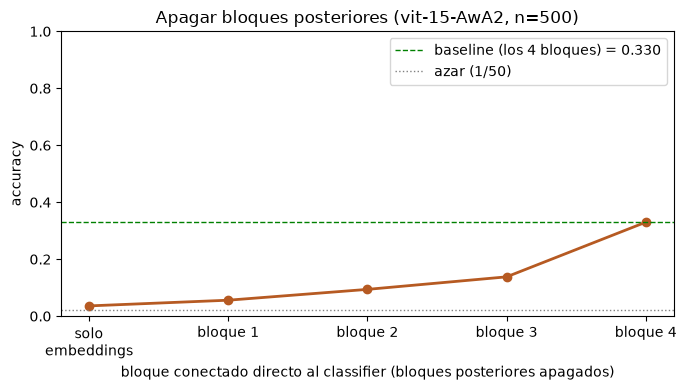

[constrained] cutoff=-1: accuracy = 0.026
[constrained] cutoff= 0: accuracy = 0.034


[constrained] cutoff= 1: accuracy = 0.088


[constrained] cutoff= 2: accuracy = 0.122


[constrained] cutoff= 3: accuracy = 0.286
guardado: experimentation/experiments/23082026_block_cutoff/block_cutoff_vit-15-constrained-AwA2.png


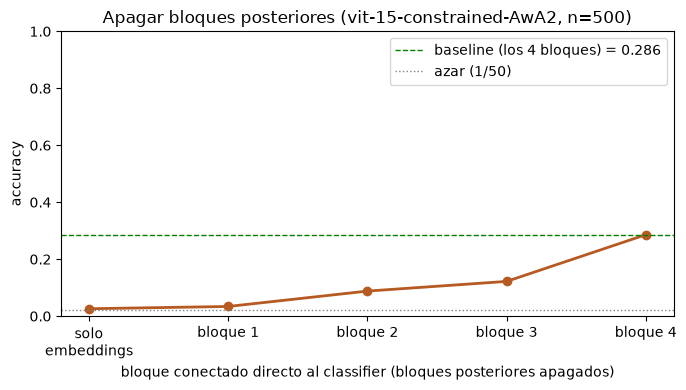

[constrained_rank] cutoff=-1: accuracy = 0.026
[constrained_rank] cutoff= 0: accuracy = 0.074


[constrained_rank] cutoff= 1: accuracy = 0.124


[constrained_rank] cutoff= 2: accuracy = 0.224


[constrained_rank] cutoff= 3: accuracy = 0.336


guardado: experimentation/experiments/23082026_block_cutoff/block_cutoff_vit-15-constrained_rank-AwA2.png


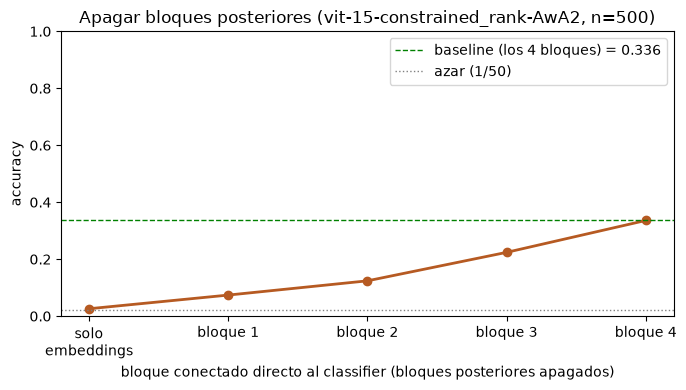

In [7]:
for key, (model, _, _) in models.items():
    cutoffs = list(range(-1, n_blocks))
    cutoff_accuracies = []
    for cutoff in cutoffs:
        logits = forward_truncated_at(model, eval_images, cutoff_block_idx=cutoff)
        acc = accuracy_of(logits, eval_labels)
        cutoff_accuracies.append(acc)
        print(f"[{key}] cutoff={cutoff:>2}: accuracy = {acc:.3f}")

    fig, ax = plt.subplots(figsize=(7, 4))
    xlabels = ["solo\nembeddings"] + [f"bloque {i+1}" for i in range(n_blocks)]
    ax.plot(range(len(cutoffs)), cutoff_accuracies, marker="o", linewidth=2, color="#b65a22")
    ax.axhline(baseline_accuracy[key], color="green", linestyle="--", linewidth=1,
               label=f"baseline (los {n_blocks} bloques) = {baseline_accuracy[key]:.3f}")
    ax.axhline(1 / num_classes, color="gray", linestyle=":", linewidth=1, label=f"azar (1/{num_classes})")
    ax.set_xticks(range(len(cutoffs)))
    ax.set_xticklabels(xlabels)
    ax.set_xlabel("bloque conectado directo al classifier (bloques posteriores apagados)")
    ax.set_ylabel("accuracy")
    ax.set_title(f"Apagar bloques posteriores ({MODELS[key]}, n={N_EVAL})")
    ax.set_ylim(0, 1)
    ax.legend()
    plt.tight_layout()
    save_fig(fig, "block_cutoff", OUTPUT_DIR, tag=MODELS[key], project_root=project_root)
    plt.show()

## Para reflexionar / siguientes pasos

- Esta curva debería verse idéntica a la de accuracy-por-capa de `logit_lens.ipynb` (ya lo comprobamos numéricamente arriba) — dos formas de llegar al mismo lugar. Si en algún momento las dos notebooks te dan números distintos, algo se rompió en una de las dos implementaciones.
- La pregunta que sí es nueva acá, comparado con `logit_lens.ipynb`: ¿tiene sentido para la tesis mostrar esto como "apagar bloques" (lenguaje de ablación/intervención) en vez de "leer capas intermedias" (lenguaje de logit lens)? Son el mismo número, pero el marco importa para cómo lo explicas en el jurado — "apagar" sugiere causalidad/intervención, "leer" sugiere solo observación pasiva.

Las curvas de baseline e interpretable ya se generan juntas arriba (una por modelo, guardadas por separado) — compararlas es el paralelo directo de lo que ya se hizo en `ablation.ipynb` y `head_contribution.ipynb`.